# Kerem Unal - Cat Breed Prediction Model
## Environment and imports

In [2]:
import torch
from torch import nn
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42)

device = torch.device("mps") #Using this since in Mac

## Data Loading and Hyperparameters

In [3]:
import kagglehub
import pathlib
from torchvision import datasets, transforms, models

path = kagglehub.dataset_download("solothok/cat-breed")

print("Path to dataset files:", path)

dataset_dir = pathlib.Path(path)

print([p.name for p in dataset_dir.iterdir()])

train_dir = dataset_dir / "cat-breed" / "TRAIN"
test_dir = dataset_dir / "cat-breed" / "TEST"

IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 6
EPOCHS = 10
LEARNING_RATE = 1e-3

Path to dataset files: /Users/keremunal/.cache/kagglehub/datasets/solothok/cat-breed/versions/1
['cat-breed']


## Transforms and Data Augmentation 

In [4]:
from torchvision.transforms import v2

train_transforms = v2.Compose([
    v2.ToImage(),
    v2.RandomResizedCrop(size=(224,224), antialias = True), #Anatalias true for fur textures
    v2.RandomHorizontalFlip(p=0.5), #Creating more images by adding random horizontalflips
    v2.RandomRotation(degrees=10), 
    #Creating more images again by adding degrees or rotation 
    #No Color changing in order to not get in front of mistaking cat breeds by color.
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transforms = v2.Compose([
    v2.ToImage(),
    v2.Resize(size=(256,256), antialias = True), 
    v2.CenterCrop(size=(224,224)),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

## DataLoading

In [5]:
from torch.utils.data import DataLoader, random_split, Subset

#Transforming the datasets to with our previous transformers
full_train_dataset = datasets.ImageFolder(root=train_dir, transform=train_transforms)
full_val_dataset = datasets.ImageFolder(root=train_dir, transform=test_transforms)
#Creating two datasets in order not the change the same data storage
#This is the full train dataset before validation and train split
test_dataset = datasets.ImageFolder(root=test_dir, transform=test_transforms)

#Creating a validation and train split 80/20
train_indices, val_indices = random_split(
    range(len(full_train_dataset)), 
    [0.8, 0.2], 
    generator=torch.Generator().manual_seed(42)
)

train_dataset = Subset(full_train_dataset, train_indices)
val_dataset   = Subset(full_val_dataset, val_indices)

#datasets into dataloaders

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4, #For apple m1 chip
)

val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False, #No shuffling for test and validation splits
    num_workers=4, #For apple m1 chip
)


test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False, #No shuffling for test and validation splits
    num_workers=4, #For apple m1 chip
)

## Transfer Learning with ResNet18

In [6]:
#Using ResNet18 since we have 6 cat breeds. 
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

for param in model.parameters():
    param.requires_grad = False 
#Freezing the parameters in order to change our features into 6

model.fc = nn.Linear(model.fc.in_features, 6) 
#Since we have 6 types of cat breeds we change the features into 6 from 1k 
# and replace the previously freezed features. 
print("New fc layer:", model.fc)

#Save Selected model parameters:
parameters = []

for p in model.parameters():
    if (p.requires_grad):
        parameters.append(p)

model = model.to(device) #Pushing the model to the device

New fc layer: Linear(in_features=512, out_features=6, bias=True)


## Optimizer and Loss Function

In [7]:
#Selecting model parameters
optimizer = torch.optim.Adam(parameters, lr=LEARNING_RATE) #Optimizer is Adam
loss_fn = nn.CrossEntropyLoss() #Loss Function is CrossEntropyLoss

## Epoch Functions

In [8]:
def evaluate(model, loader, loss_fn, device):
    model.eval() #training mode to eval mode
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for X, y in loader: #Looping by batch by batch
            X, y = X.to(device), y.to(device)
            outputs = model(X) #Runs the images through model to get the prediction scores
            loss = loss_fn(outputs, y) #Calculates the average loss of the current batch

            total_loss += loss.item() * y.size(0) 
            correct += (outputs.argmax(1) == y).sum().item() #Finding the index position
            # of the highest predicted breed and comparing it to the actual breed
            total += y.size(0) #Using y.size(0) in order to not lose correctness 
            # with the final batch
    return total_loss / total, 100 * correct / total

## Training with For Loop

In [9]:
from tqdm import tqdm

for epoch in range(EPOCHS):
    model.train()
    total_loss, train_correct, train_total = 0.0, 0, 0

    for X, y in train_loader:
        X, y = X.to(device), y.to(device)

        outputs = model(X) #Feeding the new batch
        loss = loss_fn(outputs, y) 

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        #Clear/Calculate Gradients to update weights

        total_loss += loss.item() * y.size(0) 
        train_correct += (outputs.argmax(1) == y).sum().item()
        train_total += y.size(0)

    train_loss = total_loss / train_total
    train_acc = 100 * train_correct / train_total
    val_loss, val_acc = evaluate(model, val_loader, loss_fn, device)

    print(f"Epoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss = {train_loss:.4f} and Train Accuraccy: {train_acc:.2f}%\n")
    print(f"Validation Loss = {val_loss:.4f} and Validation Accuraccy: {val_acc:.2f}%\n")

Epoch 1/10
Train Loss = 1.4923 and Train Accuraccy: 43.12%

Validation Loss = 1.0108 and Validation Accuraccy: 68.33%

Epoch 2/10
Train Loss = 0.9809 and Train Accuraccy: 71.25%

Validation Loss = 0.6910 and Validation Accuraccy: 83.33%

Epoch 3/10
Train Loss = 0.7403 and Train Accuraccy: 78.44%

Validation Loss = 0.5663 and Validation Accuraccy: 84.58%

Epoch 4/10
Train Loss = 0.6747 and Train Accuraccy: 80.31%

Validation Loss = 0.4555 and Validation Accuraccy: 89.58%

Epoch 5/10
Train Loss = 0.5889 and Train Accuraccy: 82.71%

Validation Loss = 0.4318 and Validation Accuraccy: 89.17%

Epoch 6/10
Train Loss = 0.5820 and Train Accuraccy: 81.35%

Validation Loss = 0.4083 and Validation Accuraccy: 87.92%

Epoch 7/10
Train Loss = 0.5538 and Train Accuraccy: 83.44%

Validation Loss = 0.3346 and Validation Accuraccy: 92.50%

Epoch 8/10
Train Loss = 0.5356 and Train Accuraccy: 82.92%

Validation Loss = 0.3325 and Validation Accuraccy: 91.67%

Epoch 9/10
Train Loss = 0.4865 and Train Accurac

## Evaluating on the Test Dataset

In [10]:
test_loss, test_acc = evaluate(model, test_loader, loss_fn, device)
print(f"Final Test Accuracy: {test_acc:.2f}% | Test Loss: {test_loss:.4f}")

Final Test Accuracy: 91.33% | Test Loss: 0.3129


                   precision    recall  f1-score   support

americanshorthair       0.82      0.84      0.83        50
           bengal       0.92      0.94      0.93        50
        mainecoon       0.95      0.84      0.89        50
          ragdoll       0.96      0.96      0.96        50
     scottishfold       0.88      0.92      0.90        50
           sphinx       0.94      0.98      0.96        50

         accuracy                           0.91       300
        macro avg       0.91      0.91      0.91       300
     weighted avg       0.91      0.91      0.91       300



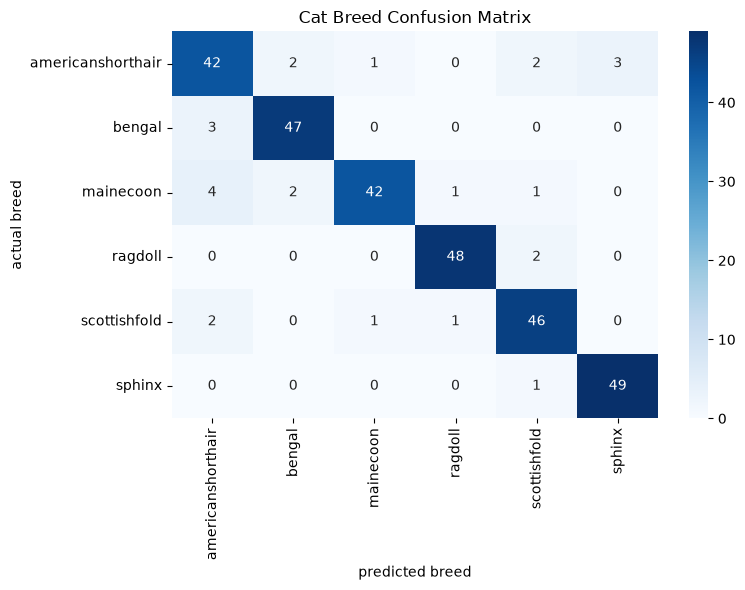

In [11]:
from sklearn.metrics import confusion_matrix, classification_report


all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for X,y in test_loader:
        X = X.to(device)
        preds = model(X).argmax(dim=1).cpu()
        all_preds.extend(preds.numpy())
        all_labels.extend(y.numpy())
#getting the results again for the test

class_names = full_train_dataset.classes
#cat breeds
print(classification_report(all_labels, all_preds, target_names=class_names))
#classification report generation 
cm = confusion_matrix(all_labels, all_preds)
#creating a confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('predicted breed')
plt.ylabel('actual breed')
plt.title('Cat Breed Confusion Matrix')
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()